# 03 Do the forecast gains carry into the portfolios?

Every model is ranked against the naive-timing benchmark `hist_rw` (σ̂²ᵢ,ₜ₊₁ = RVᵢ,ₜ, the Moreira &
Muir portfolio) twice: by forecast accuracy (section 1) and by portfolio performance (section 2).
Section 3 sets the two rankings side by side. Each ranking is shown for the cyclical bucket (pooled)
and for each ETF separately.

This notebook runs no new tests: the forecast results and tests come from e6
(`models/forecasting/evaluation/e6_overall_comparison_to_benchmark.ipynb`), the portfolio results
and tests from 02. The portfolios use the fixed σ̄² (02, Part C, covers the expanding σ̄²).
Significance: \* 10%, \*\* 5%, \*\*\* 1%.

## 0 Setup and load

The models, window and settings come from `results/portfolios/run_info.json`, the portfolio results
from 02's tables, and the forecast results from e6 (its `pooled` unit is the cyclical bucket,
`Cyclical` here). Run 01, 02 and e6 first; the asserts stop the notebook if any of them is out of
date.

In [9]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("..").resolve()))   # models/: research_config and utils

from utils.portfolio_utils import (
    PORTFOLIO_DIR, EVAL_DIR, SERIES_COLORS, BENCHMARK_COLOR, TEXT_SECONDARY, stars,
)

E6_DIR = Path("..") / "forecasting" / "results"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)

run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
SELECTED, VARIANTS, TICKERS = run_info["selected"], run_info["variants"], run_info["tickers"]
MAIN_SPEC, BENCHMARK = run_info["main_spec"], run_info["benchmark"]
MODELS = [m for m in VARIANTS if m != BENCHMARK]
FAMILY = pd.Series({m: fam for fam, ms in SELECTED.items() for m in ms}).loc[VARIANTS]
UNITS = TICKERS + ["Cyclical"]

# Portfolio side: 02's tables. Annualised Sharpe ratio and the Ledoit-Wolf test against hist_rw,
# per unit, with the cyclical bucket as the unit "Cyclical"
bucket_tbl = pd.read_csv(EVAL_DIR / f"vs_benchmarks_bucket_{MAIN_SPEC}.csv", index_col="portfolio")
etf_tbl = pd.read_csv(EVAL_DIR / f"vs_benchmarks_per_etf_{MAIN_SPEC}.csv", index_col=["model", "ETF"])
assert set(etf_tbl.index.get_level_values("model")) == set(VARIANTS), \
    "02's tables do not match run_info: rerun 02_eval_portfolios.ipynb"
pf = pd.concat([
    etf_tbl[["SR_managed", "SR_diff_vs_RW", "LW_p_vs_RW"]].rename(columns={"SR_managed": "SR"}),
    bucket_tbl.loc[VARIANTS, ["ann_sharpe", "SR_diff_vs_RW", "LW_p_vs_RW"]].rename(columns={"ann_sharpe": "SR"})
    .assign(ETF="Cyclical").set_index("ETF", append=True),
]).rename_axis(["model", "unit"])
sr_tbl = pf["SR"].unstack("unit").loc[VARIANTS, UNITS]

# Forecast side: e6's mean QLIKE, and its tests against hist_rw on the log-RV MSE
e6_losses = (pd.read_csv(E6_DIR / "e6_losses.csv").replace({"ETF": {"pooled": "Cyclical"}})
             .set_index(["model", "ETF"]))
e6_tests = pd.read_csv(E6_DIR / "e6_tests.csv").replace({"ETF": {"pooled": "Cyclical"}})
assert set(e6_tests["a"]) == set(MODELS) and (e6_tests["b"] == BENCHMARK).all(), \
    "e6 results do not match run_info: rerun e6_overall_comparison_to_benchmark.ipynb"
q = e6_losses["QLIKE"].unstack("ETF").loc[VARIANTS, UNITS]
p_logmse = (e6_tests[e6_tests["loss"] == "MSE_log"].set_index(["a", "ETF", "test"])["p_value"]
            .unstack("test").rename_axis(["model", "unit"]))   # columns: DM, Clark-West (Elastic Net only)

# Family colours for the plots; the benchmark is grey
FAMILY_COLORS = {fam: SERIES_COLORS[i] for i, fam in enumerate(f for f in SELECTED if f != FAMILY[BENCHMARK])}
color = lambda m: BENCHMARK_COLOR if m == BENCHMARK else FAMILY_COLORS[FAMILY[m]]

print("Models:", VARIANTS)
print(f"Out-of-sample: {run_info['oos_window'][0]} to {run_info['oos_window'][1]} | {MAIN_SPEC} σ̄²")

Models: ['hist_rw', 'garch', 'garch_midas_baa10y', 'en_no_macro', 'en_no_vix', 'en_vix_only', 'en_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only', 'xgb_full_macro']
Out-of-sample: 2008-03 to 2025-12 | fixed σ̄²


## 1 Forecast accuracy: ranking by QLIKE

Every model, `hist_rw` included, ranked by mean QLIKE from e6 (rank 1 = lowest QLIKE, the most
accurate). **QLIKE gain %** = (1 − QLIKE / QLIKE of `hist_rw`) × 100, so positive means more accurate
than `hist_rw`.

The significance of the difference against `hist_rw` comes from e6's tests on the **log-RV MSE**,
one-sided (H1: the model is more accurate than `hist_rw`):

- **DM p (log MSE)**: Diebold-Mariano, for every model;
- **CW p (log MSE)**: Clark-West, which e6 runs only for Elastic Net, the family whose models nest
  `hist_rw`; n/a for the others.

In [10]:
def rank_table(columns, sort_by, ascending):
    """One ranking per unit, hist_rw included: index (unit, rank), rank 1 = best."""
    out = []
    for u in UNITS:
        t = pd.DataFrame(columns(u), index=VARIANTS).rename_axis("model")
        t = t.sort_values(sort_by, ascending=ascending).reset_index()
        out.append(t.assign(unit=u, rank=range(1, len(t) + 1)))
    return pd.concat(out).set_index(["unit", "rank"])


def show_ranking(tbl, units, p_cols, title):
    """Display a ranking with its p-values as 'p stars': '–' for hist_rw, 'n/a' where no test was run."""
    out = tbl.loc[units].copy()
    for col in p_cols:
        out[col] = ["–" if m == BENCHMARK else "n/a" if pd.isna(p) else f"{p:.3f} {stars(p)}".strip()
                    for m, p in zip(out["model"], out[col])]
    if len(units) == 1:
        out = out.droplevel("unit")
    print(title)
    display(out.round(3))


FC_P = ["DM p (log MSE)", "CW p (log MSE)"]
fc_rank = rank_table(lambda u: {
    "family": FAMILY,
    "QLIKE": q[u],
    f"QLIKE gain % vs {BENCHMARK}": (1 - q[u] / q.at[BENCHMARK, u]) * 100,
    FC_P[0]: p_logmse.xs(u, level="unit")["DM"],
    FC_P[1]: p_logmse.xs(u, level="unit")["Clark-West"],
}, sort_by="QLIKE", ascending=True)

show_ranking(fc_rank, ["Cyclical"], FC_P, "Table 1a. Forecast accuracy, cyclical bucket (pooled)")

Table 1a. Forecast accuracy, cyclical bucket (pooled)


,model,family,QLIKE,QLIKE gain % vs hist_rw,DM p (log MSE),CW p (log MSE)
rank,,,,,,
1,garch,Garch,0.264,35.133,0.000 ***,n/a
2,garch_midas_baa10y,Garch,0.268,33.980,0.000 ***,n/a
3,en_vix_only,Elastic Net,0.291,28.294,0.000 ***,0.000 ***
4,en_full_macro,Elastic Net,0.325,20.080,0.008 ***,0.000 ***
5,en_no_macro,Elastic Net,0.327,19.605,0.000 ***,0.000 ***
6,xgb_vix_only,XGBoost,0.358,11.979,0.028 **,n/a
7,en_no_vix,Elastic Net,0.380,6.539,0.044 **,0.000 ***
8,xgb_full_macro,XGBoost,0.392,3.471,0.069 *,n/a
9,hist_rw,Historical,0.406,0.000,–,–


In [11]:
show_ranking(fc_rank, TICKERS, FC_P, "Table 1b. Forecast accuracy, per ETF")

Table 1b. Forecast accuracy, per ETF


model       family  QLIKE  QLIKE gain % vs hist_rw DM p (log MSE) CW p (log MSE)
unit rank                                                                                               
XLB  1     garch_midas_baa10y        Garch  0.238                   33.619      0.003 ***            n/a
     2                  garch        Garch  0.241                   32.776      0.001 ***            n/a
     3            en_vix_only  Elastic Net  0.251                   30.211      0.000 ***      0.000 ***
     4          en_full_macro  Elastic Net  0.279                   22.142      0.004 ***      0.000 ***
     5            en_no_macro  Elastic Net  0.296                   17.498      0.000 ***      0.000 ***
     6              en_no_vix  Elastic Net  0.330                    8.046        0.065 *      0.000 ***
     7                hist_rw   Historical  0.359                    0.000              –              –
     8           xgb_vix_only      XGBoost  0.365                   -1.781          0.252            n/a
     9           xgb_no_macro      XGBoost  0.378                   -5.317          0.409            n/a
     10        xgb_full_macro      XGBoost  0.392                   -9.189          0.341            n/a
     11            xgb_no_vix      XGBoost  0.422                  -17.527          0.602            n/a
XLE  1                  garch        Garch  0.255                   26.668      0.001 ***            n/a
     2     garch_midas_baa10y        Garch  0.264                   24.136      0.006 ***            n/a
     3            en_vix_only  Elastic Net  0.292                   15.992      0.009 ***      0.000 ***
     4            en_no_macro  Elastic Net  0.296                   14.853      0.006 ***      0.000 ***
     5                hist_rw   Historical  0.348                    0.000              –              –
     6          en_full_macro  Elastic Net  0.357                   -2.670          0.220      0.000 ***
     7              en_no_vix  Elastic Net  0.370                   -6.220          0.291      0.000 ***
     8           xgb_vix_only      XGBoost  0.374                   -7.537          0.304            n/a
     9         xgb_full_macro      XGBoost  0.384                  -10.232          0.290            n/a
     10          xgb_no_macro      XGBoost  0.388                  -11.374          0.477            n/a
     11            xgb_no_vix      XGBoost  0.405                  -16.398          0.379            n/a
XLF  1                  garch        Garch  0.306                   41.893      0.001 ***            n/a
     2     garch_midas_baa10y        Garch  0.312                   40.762      0.001 ***            n/a
     3            en_vix_only  Elastic Net  0.351                   33.373      0.000 ***      0.000 ***
     4          en_full_macro  Elastic Net  0.393                   25.379      0.006 ***      0.000 ***
     5            en_no_macro  Elastic Net  0.404                   23.252      0.000 ***      0.000 ***
     6           xgb_vix_only      XGBoost  0.423                   19.776       0.030 **            n/a
     7         xgb_full_macro      XGBoost  0.455                   13.565       0.029 **            n/a
     8              en_no_vix  Elastic Net  0.461                   12.475       0.041 **      0.000 ***
     9           xgb_no_macro      XGBoost  0.503                    4.526          0.261            n/a
     10               hist_rw   Historical  0.527                    0.000              –              –
     11            xgb_no_vix      XGBoost  0.579                   -9.951          0.394            n/a
XLI  1                  garch        Garch  0.261                   37.924      0.000 ***            n/a
     2     garch_midas_baa10y        Garch  0.268                   36.274      0.000 ***            n/a
     3            en_vix_only  Elastic Net  0.279                   33.594      0.004 ***      0.000 ***
     4          en_full_macro  Ela

## 2 Portfolio performance: ranking by Sharpe ratio

Every model, `hist_rw` included, ranked by the annualised Sharpe ratio of its volatility-managed
portfolio (fixed σ̄², rank 1 = highest). **ΔSR** = SR − SR(`hist_rw`), so positive means a better
portfolio than `hist_rw`. **LW p** is 02's Ledoit-Wolf test of SR = SR(`hist_rw`), a two-sided
p-value from the studentised block bootstrap.

The pooled ranking uses the cyclical bucket. The per-ETF ranking uses each ETF's managed series,
rescaled to the volatility of that ETF's own buy-and-hold.

In [12]:
PF_P = [f"LW p vs {BENCHMARK}"]
pf_rank = rank_table(lambda u: {
    "family": FAMILY,
    "SR": sr_tbl[u],
    # the ΔSR the Ledoit-Wolf test estimated (within 0.0005 of the plain difference of the SRs)
    f"ΔSR vs {BENCHMARK}": pf.xs(u, level="unit")["SR_diff_vs_RW"].fillna({BENCHMARK: 0.0}),
    PF_P[0]: pf.xs(u, level="unit")["LW_p_vs_RW"],
}, sort_by="SR", ascending=False)

show_ranking(pf_rank, ["Cyclical"], PF_P, f"Table 2a. Portfolio performance, cyclical bucket (pooled, {MAIN_SPEC} σ̄²)")

Table 2a. Portfolio performance, cyclical bucket (pooled, fixed σ̄²)


,model,family,SR,ΔSR vs hist_rw,LW p vs hist_rw
rank,,,,,
1,garch_midas_baa10y,Garch,0.499,0.031,0.458
2,garch,Garch,0.497,0.029,0.469
3,xgb_no_macro,XGBoost,0.480,0.012,0.805
4,xgb_no_vix,XGBoost,0.479,0.011,0.882
5,hist_rw,Historical,0.468,0.000,–
6,en_no_macro,Elastic Net,0.454,-0.014,0.675
7,en_vix_only,Elastic Net,0.451,-0.017,0.685
8,xgb_vix_only,XGBoost,0.420,-0.048,0.404
9,en_no_vix,Elastic Net,0.416,-0.052,0.389


In [13]:
show_ranking(pf_rank, TICKERS, PF_P, f"Table 2b. Portfolio performance, per ETF ({MAIN_SPEC} σ̄²)")

Table 2b. Portfolio performance, per ETF (fixed σ̄²)


model       family     SR  ΔSR vs hist_rw LW p vs hist_rw
unit rank                                                                        
XLB  1             xgb_no_vix      XGBoost  0.271           0.095           0.164
     2     garch_midas_baa10y        Garch  0.234           0.058           0.236
     3                  garch        Garch  0.233           0.057           0.258
     4           xgb_no_macro      XGBoost  0.227           0.051           0.448
     5            en_no_macro  Elastic Net  0.199           0.023           0.589
     6            en_vix_only  Elastic Net  0.192           0.016           0.728
     7           xgb_vix_only      XGBoost  0.192           0.015           0.806
     8                hist_rw   Historical  0.176           0.000               –
     9              en_no_vix  Elastic Net  0.174          -0.003           0.968
     10        xgb_full_macro      XGBoost  0.151          -0.026           0.713
     11         en_full_macro  Elastic Net  0.128          -0.049           0.460
XLE  1     garch_midas_baa10y        Garch  0.127           0.008           0.849
     2                  garch        Garch  0.120           0.001           0.977
     3                hist_rw   Historical  0.119           0.000               –
     4            en_vix_only  Elastic Net  0.105          -0.014           0.729
     5            en_no_macro  Elastic Net  0.101          -0.019           0.597
     6              en_no_vix  Elastic Net  0.088          -0.032           0.649
     7           xgb_no_macro      XGBoost  0.085          -0.034           0.502
     8          en_full_macro  Elastic Net  0.081          -0.038           0.582
     9           xgb_vix_only      XGBoost  0.058          -0.061           0.256
     10            xgb_no_vix      XGBoost -0.008          -0.127         0.053 *
     11        xgb_full_macro      XGBoost -0.061          -0.180       0.007 ***
XLF  1                  garch        Garch  0.596           0.074           0.313
     2     garch_midas_baa10y        Garch  0.594           0.072           0.326
     3             xgb_no_vix      XGBoost  0.586           0.064           0.560
     4            en_vix_only  Elastic Net  0.546           0.024           0.736
     5           xgb_vix_only      XGBoost  0.524           0.002           0.984
     6                hist_rw   Historical  0.522           0.000               –
     7            en_no_macro  Elastic Net  0.516          -0.007           0.851
     8           xgb_no_macro      XGBoost  0.507          -0.015           0.739
     9         xgb_full_macro      XGBoost  0.506          -0.017           0.860
     10             en_no_vix  Elastic Net  0.485          -0.038           0.626
     11         en_full_macro  Elastic Net  0.469          -0.053           0.509
XLI  1             xgb_no_vix      XGBoost  0.614           0.087           0.317
     2                  garch        Garch  0.606           0.079           0.230
     3     garch_midas_baa10y        Garch  0.580           0.053           0.430
     4           xgb_no_macro      XGBoost  0.563           0.037           0.637
     5            en_no_macro  Elastic Net  0.534           0.007           0.871
     6                hist_rw   Historical  0.527           0.000               –
     7            en_vix_only  Elastic Net  0.510          -0.017           0.798
     8           xgb_vix_only      XGBoost  0.492          -0.035           0.670
     9         xgb_full_macro      XGBoost  0.477          -0.050           0.547
     10         en_full_macro  Elastic Net  0.461          -0.066           0.358
     11             en_no_vix  Elastic Net  0.456          -0.071           0.344
XLY  1           xgb_no_macro      XGBoost  0.879           0.058           0.353
     2             xgb_no_vix      XGBoost  0.857           0.035           0.697
     3                hist_rw   Historical  0.822           0.000               –
     4

## 3 Do better forecasters build better portfolios?

The two pooled rankings side by side: every model, `hist_rw` included, ranked by mean QLIKE (Table
1a) and by the Sharpe ratio of its bucket portfolio (Table 2a). With this few models, Spearman's ρ
is descriptive, not a test.

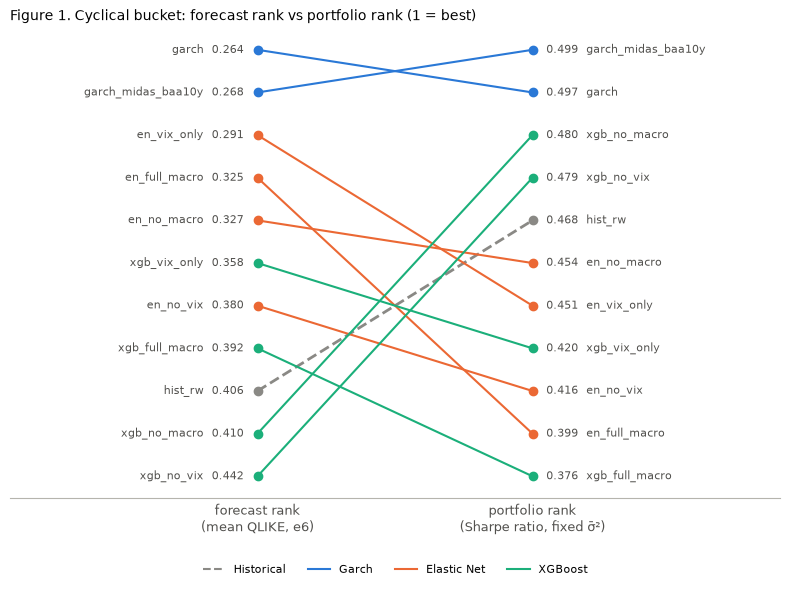

In [14]:
ranks = pd.DataFrame({
    "QLIKE": q["Cyclical"],
    "forecast_rank": q["Cyclical"].rank(method="first").astype(int),
    "SR": sr_tbl["Cyclical"],
    "portfolio_rank": sr_tbl["Cyclical"].rank(ascending=False, method="first").astype(int),
})

fig, ax = plt.subplots(figsize=(8, 6))
for m, r in ranks.iterrows():
    bench = m == BENCHMARK
    ax.plot([0, 1], [r["forecast_rank"], r["portfolio_rank"]], color=color(m), linewidth=2 if bench else 1.5,
            linestyle="--" if bench else "-", marker="o", markersize=6)
    ax.text(-0.05, r["forecast_rank"], f"{m}  {r['QLIKE']:.3f}", ha="right", va="center", fontsize=8,
            color=TEXT_SECONDARY)
    ax.text(1.05, r["portfolio_rank"], f"{r['SR']:.3f}  {m}", ha="left", va="center", fontsize=8,
            color=TEXT_SECONDARY)
ax.set_xlim(-0.9, 1.9)
ax.set_ylim(len(ranks) + 0.5, 0.5)
ax.set_xticks([0, 1], ["forecast rank\n(mean QLIKE, e6)", f"portfolio rank\n(Sharpe ratio, {MAIN_SPEC} σ̄²)"])
ax.set_yticks([])
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#b5b4ad")
ax.tick_params(colors=TEXT_SECONDARY, labelsize=9, length=0)
handles = [plt.Line2D([], [], color=BENCHMARK_COLOR, linestyle="--", label=FAMILY[BENCHMARK])]
handles += [plt.Line2D([], [], color=c, label=f) for f, c in FAMILY_COLORS.items()]
ax.legend(handles=handles, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12),
          ncol=len(handles))
ax.set_title("Figure 1. Cyclical bucket: forecast rank vs portfolio rank (1 = best)", fontsize=10, loc="left")
fig.tight_layout()
plt.show()

In [15]:
def spearman(models, unit):
    return (-q.loc[models, unit]).corr(sr_tbl.loc[models, unit], method="spearman")


rho = pd.DataFrame({u: {f"all {len(VARIANTS)} models": spearman(VARIANTS, u),
                        f"without {BENCHMARK}": spearman(MODELS, u)} for u in UNITS})
rank_summary = pd.DataFrame({
    "spearman_rho_all": rho.iloc[0],
    f"spearman_rho_without_{BENCHMARK}": rho.iloc[1],
    "best_forecast_model": q.idxmin(),
    "best_portfolio_model": sr_tbl.idxmax(),
    f"{BENCHMARK}_forecast_rank": q.rank().loc[BENCHMARK].astype(int),
    f"{BENCHMARK}_portfolio_rank": sr_tbl.rank(ascending=False).loc[BENCHMARK].astype(int),
}).rename_axis("unit")
print("Spearman ρ between −QLIKE and Sharpe ratio, per unit (descriptive)")
rho.round(2)

Spearman ρ between −QLIKE and Sharpe ratio, per unit (descriptive)


,XLB,XLE,XLF,XLI,XLY,Cyclical
all 11 models,0.11,0.87,0.35,0.16,-0.41,0.15
without hist_rw,0.10,0.87,0.43,0.20,-0.21,0.31


## Save the tables

Written to `results/eval/`: `forecast_ranking.csv` (Tables 1a and 1b), `portfolio_ranking_<spec>.csv`
(Tables 2a and 2b) and `rank_summary_<spec>.csv` (section 3), for the main σ̄². The unit
`Cyclical` is the pooled bucket.

In [16]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
fc_rank.to_csv(EVAL_DIR / "forecast_ranking.csv")
pf_rank.to_csv(EVAL_DIR / f"portfolio_ranking_{MAIN_SPEC}.csv")
rank_summary.to_csv(EVAL_DIR / f"rank_summary_{MAIN_SPEC}.csv")
print("Saved to", EVAL_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\models\portfolio_construction\results\eval
